# Comparison of some models with the data

In [1]:
from utils import *

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, f1_score, mean_squared_error, make_scorer, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

## Importing data

In [2]:
#import the data and clean it a little
raw_data = pd.read_csv("residential_solar_installations_panel_data_contiguous_US.csv", index_col=0)

features = ['avg GHI (W/m^2)',
            'ACS: number of households (2016)',
            'ACS: housing unit density (/mile^2, 2016)',
            'ACS: median household income (inflation adjusted $ in 2016, 2016)',
            'ACS: % housing units occupied (2016)',
            'ACS: % housing units occupied by renters (2016)',
            'ACS: avg number of years of education (2016)',
            'ACS: median age',
            'ACS: racial diversity (Gini Simpson index)']

columns = features + ['cumulative num of residential PVs by 2016', 'number of buildings']

raw_data = raw_data.dropna(axis=0, how='any', subset=columns) #drop all the rows that have any missing values in the columns we care about
raw_data = raw_data[raw_data['number of buildings']>0] #only keep rows with at least some buildings in them

In [3]:
#group by county
blockgroups_fips = [fips if len(fips)==12 else '0'+fips for fips in raw_data.index.astype(str).values]
county_codes = [fips[:5] for fips in blockgroups_fips]

raw_data['County code'] = county_codes

columns += ['County code']

raw_data = raw_data[columns].groupby('County code').agg({
    'avg GHI (W/m^2)':'mean', 
    'ACS: number of households (2016)':'sum', 
    'ACS: housing unit density (/mile^2, 2016)':'mean',
    'ACS: median household income (inflation adjusted $ in 2016, 2016)':'median', 
    'ACS: % housing units occupied (2016)':'mean', 
    'ACS: % housing units occupied by renters (2016)':'mean',
    'ACS: avg number of years of education (2016)':'mean', 
    'ACS: median age': 'median', 
    'ACS: racial diversity (Gini Simpson index)':'mean',
    'cumulative num of residential PVs by 2016':'sum',
    'number of buildings':'sum'
})

## Regression

In [4]:
features = ['avg GHI (W/m^2)',
            'ACS: number of households (2016)',
            'ACS: housing unit density (/mile^2, 2016)',
            'ACS: median household income (inflation adjusted $ in 2016, 2016)',
            'ACS: % housing units occupied (2016)',
            'ACS: % housing units occupied by renters (2016)',
            'ACS: avg number of years of education (2016)',
            'ACS: median age',
            'ACS: racial diversity (Gini Simpson index)']

X = raw_data[features].to_numpy()
y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# X_train, X_test, y_train, y_test = train_test_split(X[y.flatten()!=0], y[y.flatten()!=0], test_size=0.2, random_state=42)

### Linear regressions

In [6]:
alphas = np.logspace(-7, 3, 200)
scores = []

for alpha in alphas:
    model = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=alpha))])
    scores.append(cross_val_score(model, X_train, y_train, cv=5, n_jobs=5))
    
scores = np.array(scores)

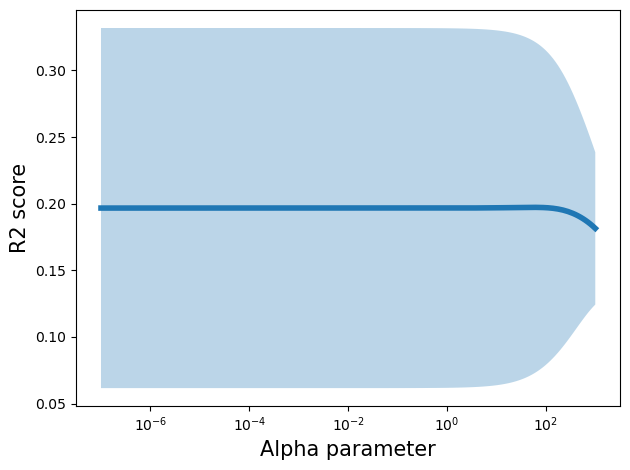

In [7]:
fig, ax = plt.subplots()

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax.plot(alphas, means, linewidth=4)
ax.fill_between(alphas, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax.set_xlabel("Alpha parameter", fontsize=15)
ax.set_ylabel("R2 score", fontsize=15)
ax.tick_params(labelsize=10)
ax.set_xscale('log')

fig.tight_layout()

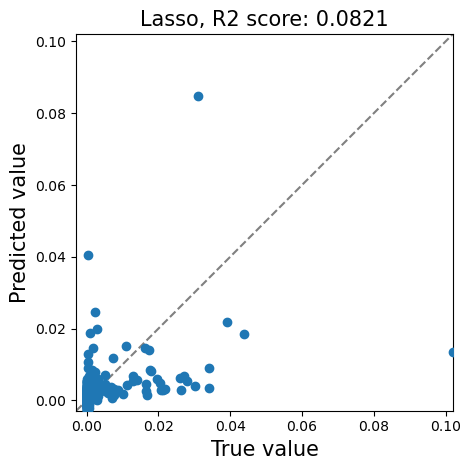

In [8]:
fig, ax = plt.subplots()

model = Pipeline([('scale', StandardScaler()), ('model', Lasso(alpha=1e-4))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

ax.scatter(y_test, y_pred, zorder=10)
minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax.plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax.set_xlabel("True value", fontsize=15)
ax.set_ylabel("Predicted value", fontsize=15)
ax.set_xlim(minval, maxval)
ax.set_ylim(minval, maxval)
ax.set_aspect(1)

ax.set_title(f"Lasso, R2 score: {r2_score(y_test, y_pred):.4f}", fontsize=15)

fig.tight_layout()
# fig.savefig("images/lasso_score.png", dpi=150)

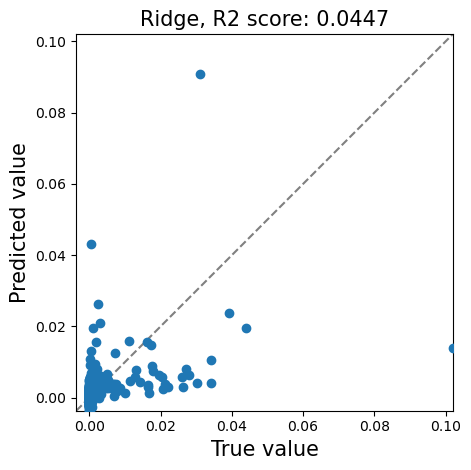

In [9]:
fig, ax = plt.subplots()

model = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=1e-4))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

ax.scatter(y_test, y_pred, zorder=10)
minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax.plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax.set_xlabel("True value", fontsize=15)
ax.set_ylabel("Predicted value", fontsize=15)
ax.set_xlim(minval, maxval)
ax.set_ylim(minval, maxval)
ax.set_aspect(1)

ax.set_title(f"Ridge, R2 score: {r2_score(y_test, y_pred):.4f}", fontsize=15)

fig.tight_layout()
# fig.savefig("images/ridge_score.png", dpi=150)

### Forest based methods

In [22]:
n_ests = np.linspace(10, 200, 25).astype(int)
scores = []

timer = IterTimer(len(n_ests))

for n_est in n_ests:
    timer.start_iter()
    model = RandomForestRegressor(n_estimators=n_est, n_jobs=8)
    scores.append(cross_val_score(model, X_train, y_train.flatten(), cv=5))
    timer.end_iter()
    
scores = np.array(scores)

Iteration 25/25, ETA: 21:50:17 (average time per iteration: 0.947s)


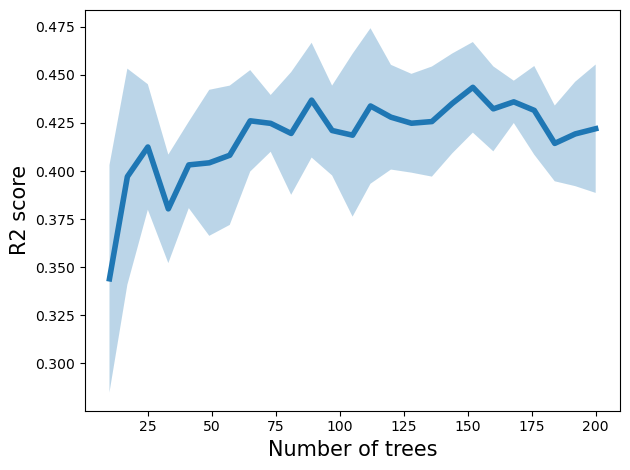

In [23]:
fig, ax = plt.subplots()

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax.plot(n_ests, means, linewidth=4)
ax.fill_between(n_ests, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax.set_xlabel("Number of trees", fontsize=15)
ax.set_ylabel("R2 score", fontsize=15)
ax.tick_params(labelsize=10)

fig.tight_layout()

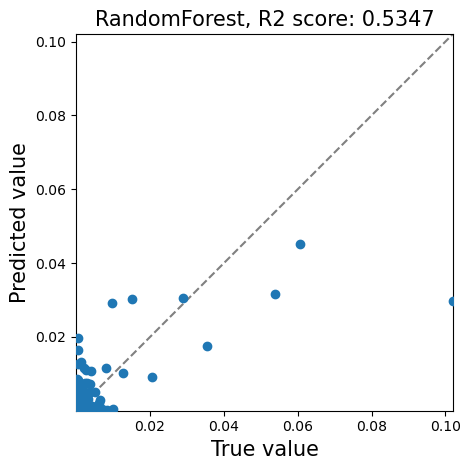

In [17]:
fig, ax = plt.subplots()

model = RandomForestRegressor(n_estimators=200, n_jobs=8)
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

ax.scatter(y_test, y_pred, zorder=10)
minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax.plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax.set_xlabel("True value", fontsize=15)
ax.set_ylabel("Predicted value", fontsize=15)
ax.set_xlim(minval, maxval)
ax.set_ylim(minval, maxval)
ax.set_aspect(1)

ax.set_title(f"RandomForest, R2 score: {r2_score(y_test, y_pred):.4f}", fontsize=15)

fig.tight_layout()
# fig.savefig("images/RF_score.png", dpi=150)

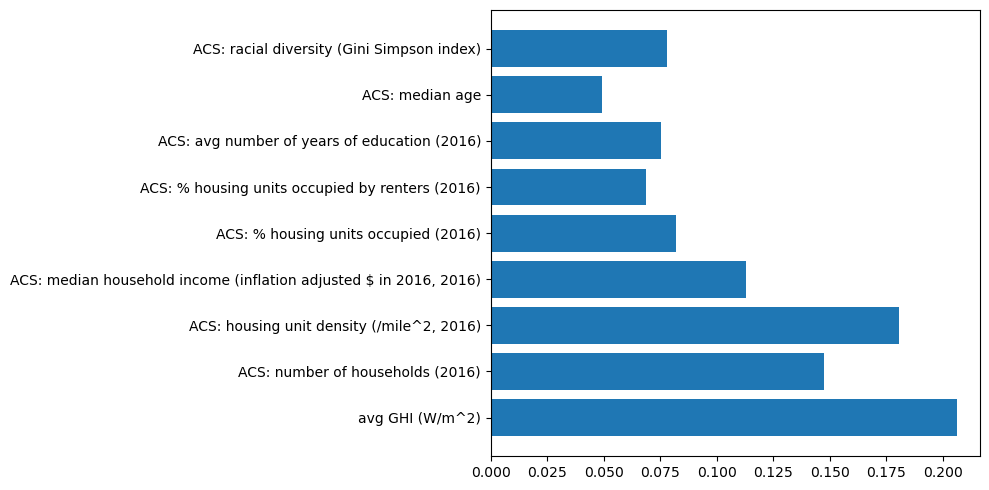

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(range(len(features)), model.feature_importances_)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features);

fig.tight_layout()

In [25]:
n_ests = np.linspace(50, 300, 50).astype(int)
scores = []

timer = IterTimer(len(n_ests))

for n_est in n_ests:
    timer.start_iter()
    model = GradientBoostingRegressor(n_estimators=n_est)
    scores.append(cross_val_score(model, X_train, y_train.flatten(), cv=5, n_jobs=5))
    timer.end_iter()
    
scores = np.array(scores)

Iteration 50/50, ETA: 21:51:20 (average time per iteration: 0.589s)


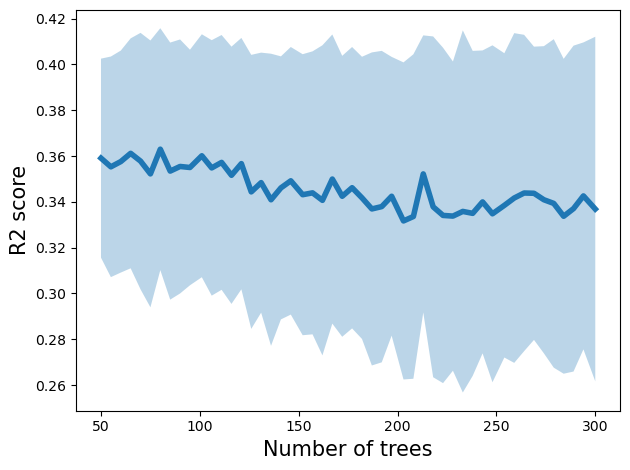

In [26]:
fig, ax = plt.subplots()

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax.plot(n_ests, means, linewidth=4)
ax.fill_between(n_ests, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax.set_xlabel("Number of trees", fontsize=15)
ax.set_ylabel("R2 score", fontsize=15)
ax.tick_params(labelsize=10)

fig.tight_layout()

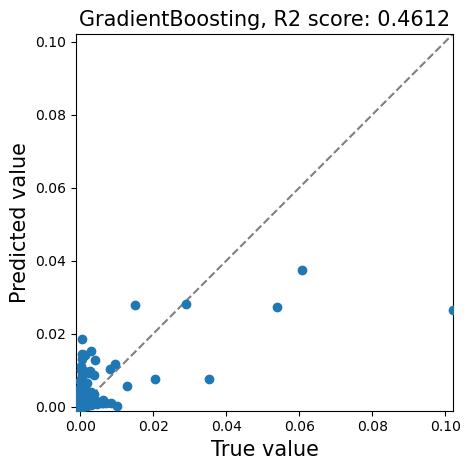

In [19]:
fig, ax = plt.subplots()

model = GradientBoostingRegressor(n_estimators=50)
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

ax.scatter(y_test, y_pred, zorder=10)
minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax.plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax.set_xlabel("True value", fontsize=15)
ax.set_ylabel("Predicted value", fontsize=15)
ax.set_xlim(minval, maxval)
ax.set_ylim(minval, maxval)
ax.set_aspect(1)

ax.set_title(f"GradientBoosting, R2 score: {r2_score(y_test, y_pred):.4f}", fontsize=15)

fig.tight_layout()
# fig.savefig("images/GB_score.png", dpi=150)

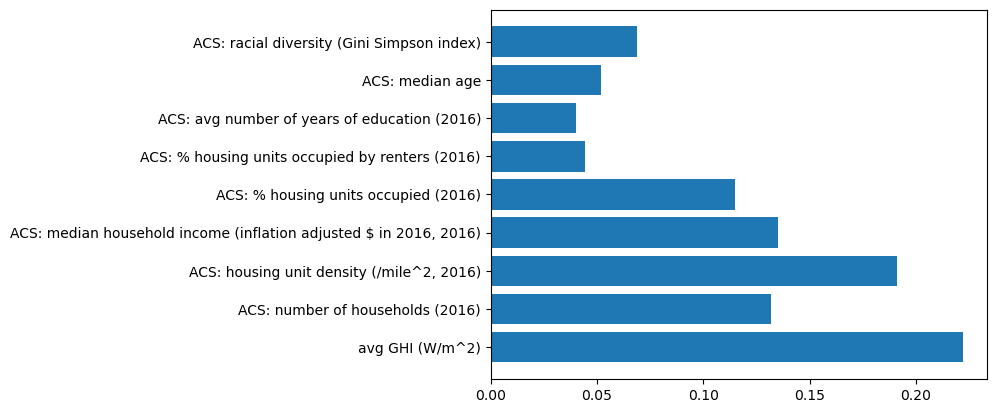

In [20]:
fig, ax = plt.subplots()

ax.barh(range(len(features)), model.feature_importances_)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features);

# fig.tight_layout()

## Classification
Since 38.80% of the data is just 0s, maybe our models would benefit from a two step process where we first classify into `has panels` and `does not have panels` before doing regression for the `has panels`.

In [5]:
features = ['avg GHI (W/m^2)',
            'ACS: number of households (2016)',
            'ACS: housing unit density (/mile^2, 2016)',
            'ACS: median household income (inflation adjusted $ in 2016, 2016)',
            'ACS: % housing units occupied (2016)',
            'ACS: % housing units occupied by renters (2016)',
            'ACS: avg number of years of education (2016)',
            'ACS: median age',
            'ACS: racial diversity (Gini Simpson index)']

X = raw_data[features].to_numpy()
y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y!=0, test_size=0.2, random_state=42)

### Forest base methods

In [30]:
n_ests = np.linspace(10, 200, 25).astype(int)
scores = []

timer = IterTimer(len(n_ests))

for n_est in n_ests:
    timer.start_iter()
    model = RandomForestClassifier(n_estimators=n_est, n_jobs=8)
    scores.append(cross_val_score(model, X_train, y_train.flatten(), cv=5, scoring=make_scorer(f1_score)))
    timer.end_iter()
    
scores = np.array(scores)

Iteration 25/25, ETA: 22:01:12 (average time per iteration: 0.582s)


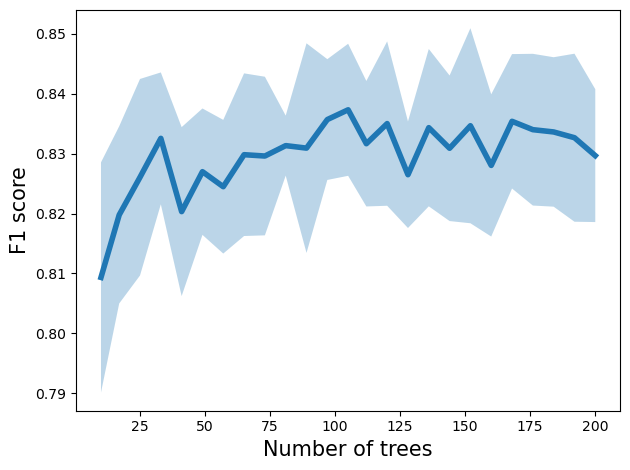

In [31]:
fig, ax = plt.subplots()

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax.plot(n_ests, means, linewidth=4)
ax.fill_between(n_ests, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax.set_xlabel("Number of trees", fontsize=15)
ax.set_ylabel("F1 score", fontsize=15)
ax.tick_params(labelsize=10)

fig.tight_layout()

0.8579


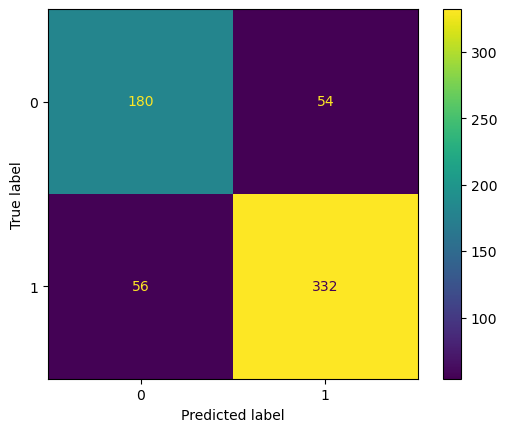

In [46]:
model = RandomForestClassifier(n_estimators=200, n_jobs=8)
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

print(f"{f1_score(y_test, y_pred):.4f}")
cm = confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(cm).plot()

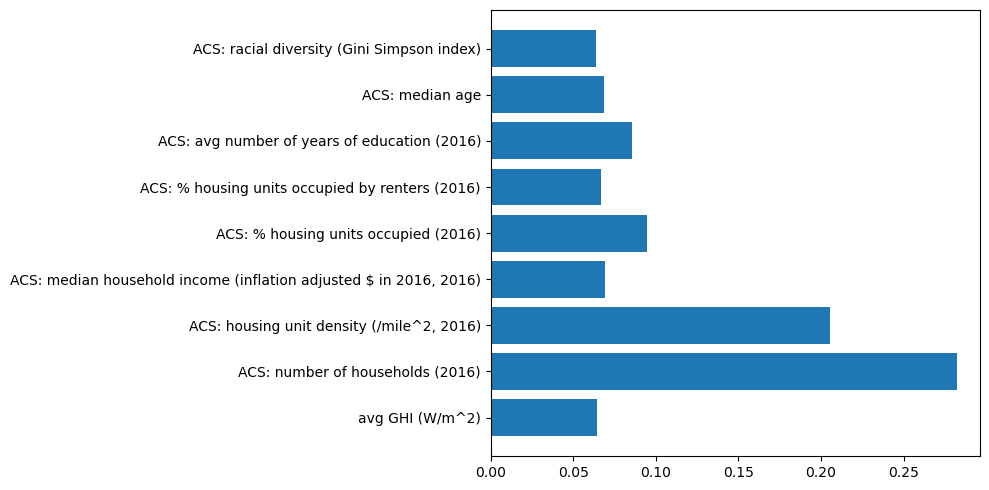

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(range(len(features)), model.feature_importances_)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features);

fig.tight_layout()

In [39]:
n_ests = np.linspace(50, 300, 50).astype(int)
scores = []

timer = IterTimer(len(n_ests))

for n_est in n_ests:
    timer.start_iter()
    model = GradientBoostingClassifier(n_estimators=n_est)
    scores.append(cross_val_score(model, X_train, y_train.flatten(), cv=5, n_jobs=5, scoring=make_scorer(f1_score)))
    timer.end_iter()
    
scores = np.array(scores)

Iteration 50/50, ETA: 22:04:10 (average time per iteration: 0.942s)


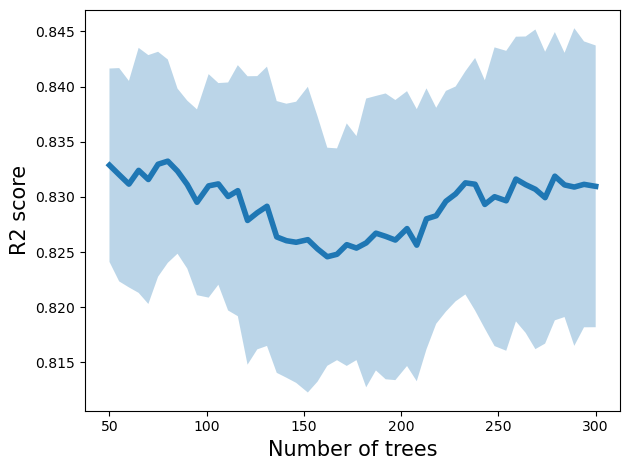

In [40]:
fig, ax = plt.subplots()

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax.plot(n_ests, means, linewidth=4)
ax.fill_between(n_ests, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax.set_xlabel("Number of trees", fontsize=15)
ax.set_ylabel("R2 score", fontsize=15)
ax.tick_params(labelsize=10)

fig.tight_layout()

0.8450


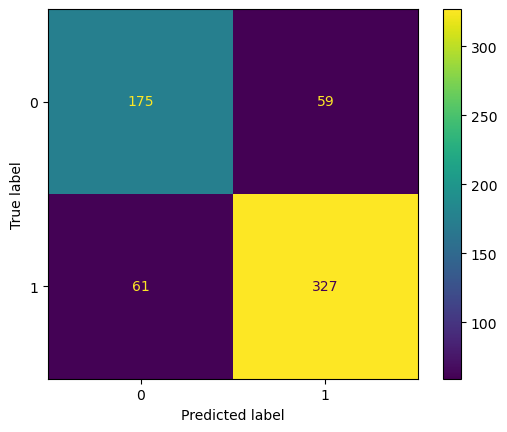

In [45]:
model = GradientBoostingClassifier(n_estimators=300)
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

print(f"{f1_score(y_test, y_pred):.4f}")
cm = confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(cm).plot()

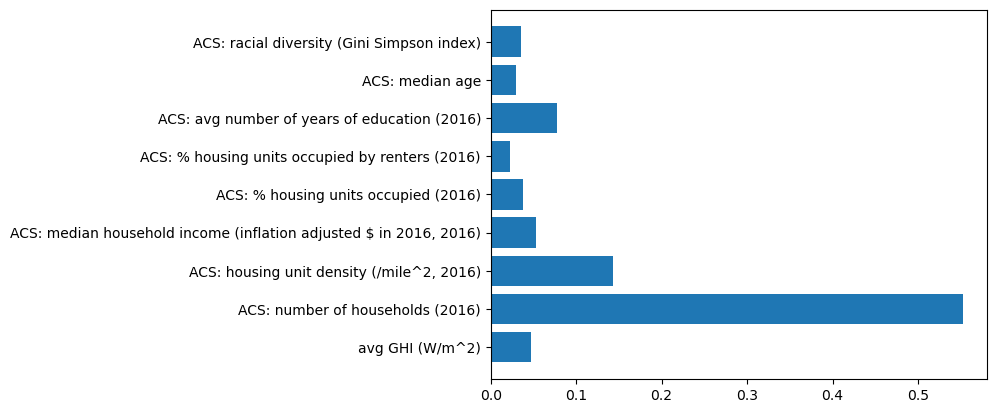

In [44]:
fig, ax = plt.subplots()

ax.barh(range(len(features)), model.feature_importances_)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features);

# fig.tight_layout()